# Goldwind green bond screener: credit profile, GBP alignment and use-of-proceeds classification

**Case bond:** 26金风科技MTN002 (code 102683199), RMB 1bn 3+N perpetual medium-term note (yǒng xù zhōng qī piào jù), 2.00% coupon, issued 19 Aug 2026. The prospectus states the issuer *intends* to book it as equity (pp. 6, 24).

**Questions**
1. How has Goldwind's credit profile moved, and what drove the latest change?
2. Does issuing MTN002 change that profile?
3. How well does the bond's documentation meet the Green Bond Principles (GBP)?
4. Can an LLM classify the bond's use of proceeds into the green-project catalogue?

**Data.** Annual statements FY2004-FY2025 (audited), the H1 2026 report (unaudited), the MTN002 prospectus, the second-party opinion (SPO) and 9 other green bond prospectuses for the classifier. Credit ratios exist from FY2017 only, because earlier years lack the interest and debt inputs.

**Units.** RMB 亿元 (yì yuán, 100 million) unless stated. LTM = FY2025 + H1 2026 - H1 2025 for flows; balance items at 30 June 2026.

All results are recomputed from the CSVs in `data/` and `outputs/`; nothing is typed in by hand except where a cell cites a prospectus page.

In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
for sub in ["data/processed", "data/labels", "data/prospectus"]:
    print("==", sub)
    for p in sorted((ROOT / sub).glob("*.csv")):
        df = pd.read_csv(p)
        print(f"{p.name}: {df.shape[0]} rows x {df.shape[1]} cols")
        print("   ", list(df.columns))

== data/processed
gbp_scores_detail.csv: 14 rows x 9 cols
    ['bond', 'pillar', 'criterion_id', 'criterion', 'score', 'confidence', 'source_pages', 'evidence_zh', 'rationale']
gbp_scores_summary.csv: 5 rows x 5 cols
    ['bond', 'pillar', 'score', 'max', 'pct']
goldwind_credit_inputs_annual.csv: 22 rows x 16 cols
    ['year', 'revenue', 'pretax_profit', 'interest_expense', 'investment_income', 'fair_value_gain', 'ebit', 'da', 'ebitda', 'cash', 'total_debt', 'long_term_payables', 'total_debt_broad', 'total_liabilities', 'total_assets', 'other_equity_instruments']
goldwind_credit_ratios_annual.csv: 22 rows x 12 cols
    ['year', 'interest_coverage', 'ebitda_interest_coverage', 'debt_to_ebitda', 'debt_to_ebitda_broad', 'debt_to_ebitda_change', 'net_debt_to_ebitda', 'liabilities_to_assets_pct', 'adj_interest_coverage', 'adj_debt_to_ebitda', 'adj_debt_hybrid_to_ebitda', 'liabilities_hybrid_to_assets_pct']
goldwind_credit_ratios_ltm.csv: 1 rows x 12 cols
    ['year', 'interest_coverage', 'e

In [2]:
import sys
sys.path.insert(0, str(ROOT / "src"))

annual = pd.read_csv(ROOT / "data/processed/goldwind_credit_ratios_annual.csv")
inputs = pd.read_csv(ROOT / "data/processed/goldwind_credit_inputs_annual.csv")
ltm = pd.read_csv(ROOT / "data/processed/goldwind_credit_ratios_ltm.csv")

pd.set_option("display.width", 250, "display.max_columns", 30)
print(annual["year"].tolist())
print(annual.tail(5).round(2).to_string(index=False))
print(ltm.round(2).to_string(index=False))

[2025, 2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007, 2006, 2005, 2004]
 year  interest_coverage  ebitda_interest_coverage  debt_to_ebitda  debt_to_ebitda_broad  debt_to_ebitda_change  net_debt_to_ebitda  liabilities_to_assets_pct  adj_interest_coverage  adj_debt_to_ebitda  adj_debt_hybrid_to_ebitda  liabilities_hybrid_to_assets_pct
 2008                NaN                       NaN             NaN                   NaN                    NaN                 NaN                      63.09                    NaN                 NaN                        NaN                             63.09
 2007                NaN                       NaN             NaN                   NaN                    NaN                 NaN                      46.07                    NaN                 NaN                        NaN                             46.07
 2006                NaN                       NaN             NaN            

In [3]:
from credit_ratios_ltm import build_ltm_row

ltm_inputs = build_ltm_row()
print(type(ltm_inputs))
print(ltm_inputs.T)

print("== outputs/")
for p in sorted((ROOT / "outputs").iterdir()):
    print(p.name, p.stat().st_size)

<class 'pandas.DataFrame'>
year                             2026
pretax_profit               43.576002
interest_expense             9.896212
investment_income            8.048908
fair_value_gain              7.370498
da                          44.284754
ebit                        53.472214
ebitda                      97.756968
cash                       112.963461
total_debt                 391.314945
total_debt_broad           430.883845
total_liabilities         1227.236208
total_assets              1709.087749
other_equity_instruments    50.430000
== outputs/
charts 0
error_view.txt 28443
eval_per_bond.csv 1479
eval_summary.txt 2116
labeling_view.txt 28882
llm_cache 4096
llm_predictions.csv 18971
llm_prompt_preview.txt 33044


## 1. Credit ratios, FY2017-FY2025 and LTM to 30 June 2026

Each ratio is shown in up to three views: **reported**; **adjusted**, with 投资收益 (tóu zī shōu yì, investment income) and 公允价值变动收益 (fair-value gains) removed from EBITDA/EBIT; and **perpetuals as debt**, adding 其他权益工具 (qí tā quán yì gōng jù, other equity instruments) to debt or liabilities.

- Reported debt/EBITDA was 3.6-4.1x in 2017-2021, 5.4-5.9x in 2022-2024, 3.95x in 2025 and 4.00x LTM.
- Reported EBIT interest coverage fell from 5.0x (2021) to 2.7x (2024), then recovered to 4.77x (2025) and 5.40x LTM. Excluding investment and fair-value gains it was about 1x in 2023-2024 (read off the chart).
- Liabilities/assets (资产负债率, zī chǎn fù zhài lǜ) rose from 67.75% (2017) to 73.96% (2024), then 71.66% (2025) and 71.81% LTM. Counting perpetuals as liabilities adds 2.8 points in 2025 and 2.95 points LTM (74.76%).

**Reading notes.** The right panel's y-axis is truncated. The LTM marker is hollow and not connected, because its window overlaps FY2025. H1 2026 is unaudited.

**Caveat on "adjusted".** It removes all of 投资收益. If that line includes recurring items (income from associates, wind-farm project disposals) the adjusted view is a conservative bound, not "true" earnings. Its composition (年报 附注, nián bào fù zhù) has not been checked.

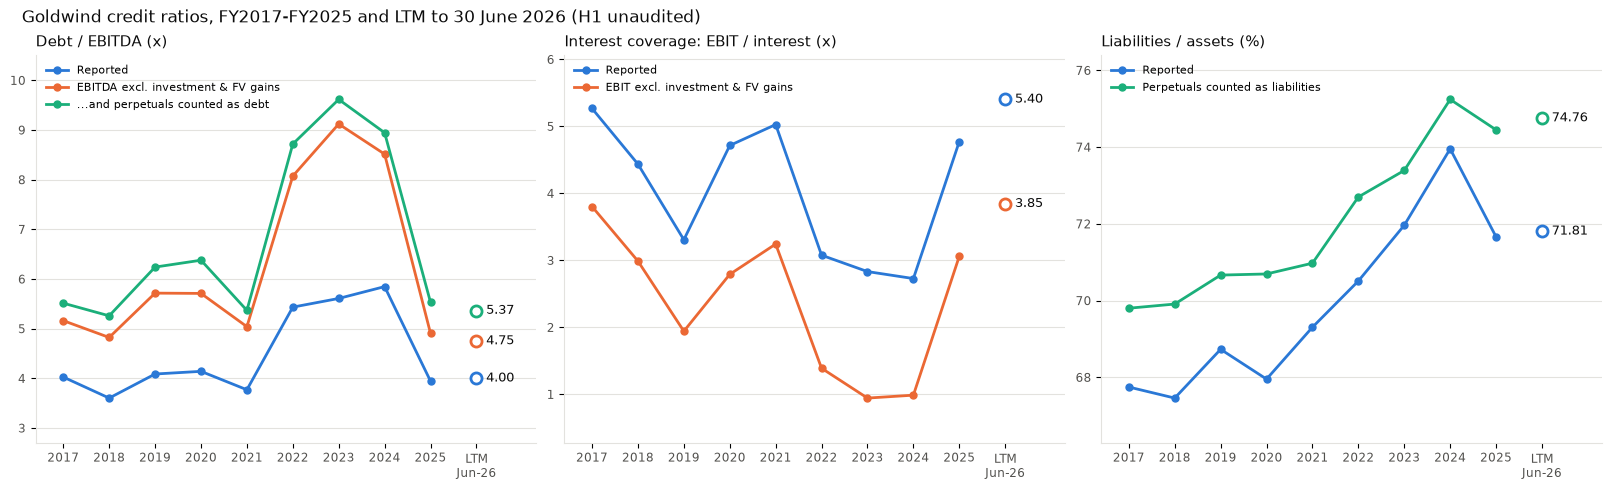

In [4]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e3e2de"

hist = annual[annual["year"] >= 2017].sort_values("year")
cur = ltm.iloc[0]

panels = [
    ("Debt / EBITDA (x)", [
        ("debt_to_ebitda", BLUE, "Reported"),
        ("adj_debt_to_ebitda", ORANGE, "EBITDA excl. investment & FV gains"),
        ("adj_debt_hybrid_to_ebitda", AQUA, "...and perpetuals counted as debt"),
    ]),
    ("Interest coverage: EBIT / interest (x)", [
        ("interest_coverage", BLUE, "Reported"),
        ("adj_interest_coverage", ORANGE, "EBIT excl. investment & FV gains"),
    ]),
    ("Liabilities / assets (%)", [
        ("liabilities_to_assets_pct", BLUE, "Reported"),
        ("liabilities_hybrid_to_assets_pct", AQUA, "Perpetuals counted as liabilities"),
    ]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
xt = list(range(2017, 2026)) + [2026]
xl = [str(y) for y in range(2017, 2026)] + ["LTM\nJun-26"]

for ax, (title, series) in zip(axes, panels):
    for col, color, lab in series:
        ax.plot(hist["year"], hist[col], color=color, lw=2, marker="o", ms=5, label=lab)
        ax.plot([2026], [cur[col]], ls="none", marker="o", ms=8, mfc="white", mec=color, mew=2)
        ax.annotate(f"{cur[col]:.2f}", (2026, cur[col]), xytext=(7, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, fontsize=8.5, color=MUTED)
    ax.set_xlim(2016.4, 2027.3)
    ax.margins(y=0.15)
    ax.tick_params(axis="y", labelsize=8.5, labelcolor=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.legend(frameon=False, fontsize=8, loc="upper left")

fig.suptitle("Goldwind credit ratios, FY2017-FY2025 and LTM to 30 June 2026 (H1 unaudited)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.savefig(ROOT / "outputs/charts/credit_trends.png", dpi=160, facecolor="white")
plt.show()

## 2. What drove the 2025 fall in leverage

| 亿元 | 2021 | 2022 | 2023 | 2024 | 2025 | LTM |
|---|---|---|---|---|---|---|
| EBITDA | 81.4 | 68.9 | 67.4 | 67.6 | 92.4 | 97.8 |
| Investment income + fair-value gains | 20.5 | 22.5 | 25.9 | 21.2 | 18.1 | 15.4 |
| Gains as % of EBITDA | 25.2 | 32.7 | 38.5 | 31.3 | 19.6 | 15.8 |
| Total debt | 307.0 | 374.5 | 378.0 | 395.4 | 364.4 | 391.3 |
| Perpetuals (其他权益工具) | 20.0 | 30.0 | 20.5 | 20.0 | 46.4 | 50.4 |

Debt/EBITDA fell from 5.85x (2024) to 3.95x (2025), a change of -1.90x.

- **From EBITDA:** -1.57x (EBITDA 67.6 to 92.4, +37%). **From debt:** -0.34x (395.4 to 364.4).
- The debt effect is mostly a swap into perpetuals: the perpetuals balance rose from 20.0 to 46.4, so debt plus perpetuals fell only from 415.4 to 410.8 (about 1%). With perpetuals counted as debt, the ratio fell from 6.14x to 4.45x, of which -1.65x is EBITDA and -0.05x is debt.
- The EBITDA recovery is not a gains effect. EBITDA excluding gains rose from 46.4 to 74.3 (+60%) while total gains fell from 21.2 to 18.1. Their mix changed: investment income fell from 19.6 to 7.3 and fair-value gains rose from 1.6 to 10.8. The nature of the 10.8 fair-value gain has not been verified.
- LTM: debt rose 7.4% (364.4 to 391.3) against EBITDA +5.8% (92.4 to 97.8), so debt/EBITDA is flat at 4.00x.

**So:** the 2025 "deleveraging" is an earnings recovery, not a reduction in the debt burden. The change in the perpetuals balance is a balance-sheet difference, not an issuance figure; it is also affected by distributions and redemptions.

In [5]:
base_cols = ["ebitda", "investment_income", "fair_value_gain", "total_debt",
             "other_equity_instruments", "cash"]
t = pd.concat([
    inputs.set_index("year").sort_index().loc[2021:2025, base_cols],
    ltm_inputs[base_cols],
])
t["gains"] = t["investment_income"] + t["fair_value_gain"]
t["gains_pct_of_ebitda"] = t["gains"] / t["ebitda"] * 100
t["ebitda_ex_gains"] = t["ebitda"] - t["gains"]
t["debt_to_ebitda"] = t["total_debt"] / t["ebitda"]
t["debt_to_ebitda_ex_gains"] = t["total_debt"] / t["ebitda_ex_gains"]
t["debt_hybrid_to_ebitda_ex_gains"] = (t["total_debt"] + t["other_equity_instruments"]) / t["ebitda_ex_gains"]
print(t.round(2).to_string())

d24, e24 = t.loc[2024, "total_debt"], t.loc[2024, "ebitda"]
d25, e25 = t.loc[2025, "total_debt"], t.loc[2025, "ebitda"]
eff_e = d24 / e25 - d24 / e24
eff_d = (d25 - d24) / e25
print()
print(f"Debt/EBITDA 2024 -> 2025: {d24/e24:.2f} -> {d25/e25:.2f}  (change {d25/e25 - d24/e24:+.2f})")
print(f"  from EBITDA {e24:.1f} -> {e25:.1f} at constant debt : {eff_e:+.2f}")
print(f"  from debt   {d24:.1f} -> {d25:.1f} at 2025 EBITDA   : {eff_d:+.2f}")

      ebitda  investment_income  fair_value_gain  total_debt  other_equity_instruments    cash  gains  gains_pct_of_ebitda  ebitda_ex_gains  debt_to_ebitda  debt_to_ebitda_ex_gains  debt_hybrid_to_ebitda_ex_gains
year                                                                                                                                                                                                                
2021   81.38              19.83             0.66      306.98                     19.97   85.77  20.50                25.19            60.88            3.77                     5.04                            5.37
2022   68.89              23.68            -1.17      374.48                     29.96  156.28  22.51                32.67            46.38            5.44                     8.07                            8.72
2023   67.38              22.46             3.49      378.03                     20.50  142.45  25.94                38.50            41.44         

## 3. Pro-forma: does MTN002 change the credit profile?

Base is the LTM balance sheet at 30 June 2026, which predates the issue (19 Aug 2026). Issue size is 10 亿元; the coupon is 2.00%.

| Scenario | Treatment | Balance-sheet effect |
|---|---|---|
| Base | No MTN002 | as reported |
| A | Equity, proceeds held as cash | assets +10, cash +10, perpetuals +10 |
| B | Equity, proceeds repay debt | debt -10, liabilities -10, perpetuals +10 |
| C | Reclassified as debt (a risk the prospectus lists, p. 19), proceeds held as cash | debt +10, liabilities +10, assets +10, cash +10, interest +0.2 |

| | Base | A | B | C |
|---|---|---|---|---|
| Debt/EBITDA | 4.00x | 4.00x | 3.90x | 4.11x |
| Net debt/EBITDA | 2.85x | 2.75x | 2.75x | 2.85x |
| Liabilities/assets | 71.81% | 71.39% | 71.22% | 71.97% |
| EBIT interest coverage | 5.40x | 5.40x | 5.40x | 5.29x |
| Perpetuals as debt, EBITDA excl. gains | 5.37x | 5.49x | 5.37x | 5.49x |

The Base row is tested against `goldwind_credit_ratios_ltm.csv` inside the cell.

**Finding.** Debt/EBITDA moves within 3.90x-4.11x and coverage by at most 0.11x. The equity-versus-debt treatment (0.21x) is small next to the 1.9x change between 2024 and 2025. MTN002 does not materially change the credit profile.

**Prospectus claim not reproduced.** Prospectus p. 19 says liabilities/assets falls by about 1.02% versus FY2025. On the FY2025 balance sheet (p. 109: assets 16,649,520.39 and liabilities 11,931,446.04, 万元) the result is -0.43 points (cash) or -0.60 points (debt repaid). Reaching -1.02 points at constant assets needs liabilities to fall by about 17 亿元, 1.7 times the issue size. Prospectus p. 143 itself says the effect on the ratio is limited ("影响不大"). The gap is unexplained.

**Not modelled.** Interest saved if the proceeds repay debt (the rate on that debt is unknown); the actual allocation of proceeds, which is unknown until the first use-of-proceeds report. A and B are bounds, not forecasts.

In [6]:
import numpy as np

row = ltm_inputs.iloc[0]
ISSUE = 10.0     # RMB 1bn in 亿元
COUPON = 0.02    # 2.00% p.a.

adj_adj = row["investment_income"] + row["fair_value_gain"]

def metrics(debt, cash, liab, assets, perp, interest):
    return {
        "debt_to_ebitda": debt / row["ebitda"],
        "net_debt_to_ebitda": (debt - cash) / row["ebitda"],
        "liabilities_to_assets_pct": liab / assets * 100,
        "interest_coverage": row["ebit"] / interest,
        "adj_debt_hybrid_to_ebitda": (debt + perp) / (row["ebitda"] - adj_adj),
        "liabilities_hybrid_to_assets_pct": (liab + perp) / assets * 100,
    }

base = dict(debt=row["total_debt"], cash=row["cash"], liab=row["total_liabilities"],
            assets=row["total_assets"], perp=row["other_equity_instruments"],
            interest=row["interest_expense"])

def shift(**d):
    s = dict(base)
    for k, v in d.items():
        s[k] += v
    return s

scen = {
    "Base (no MTN002)": base,
    "A equity, held as cash": shift(cash=ISSUE, assets=ISSUE, perp=ISSUE),
    "B equity, repays debt": shift(debt=-ISSUE, liab=-ISSUE, perp=ISSUE),
    "C reclassified as debt": shift(debt=ISSUE, cash=ISSUE, liab=ISSUE, assets=ISSUE,
                                    interest=ISSUE * COUPON),
}
proforma = pd.DataFrame({k: metrics(**v) for k, v in scen.items()}).T

# self-test: Base must equal the LTM file
for c in proforma.columns:
    assert np.isclose(proforma.loc["Base (no MTN002)", c], ltm.loc[0, c], atol=0.01), c
print("Base matches goldwind_credit_ratios_ltm.csv")

print(proforma.round(2).to_string())
print()
print((proforma - proforma.loc["Base (no MTN002)"]).round(2).to_string())

# prospectus check, FY2025 (prospectus p.109: assets 16,649,520.39 and liabilities 11,931,446.04, 万元)
A, L = 1664.952039, 1193.144604
r0 = L / A * 100
print()
print(f"FY2025 liabilities/assets: {r0:.2f}%")
print(f"  equity, held as cash : {L / (A + ISSUE) * 100:.2f}%  ({L / (A + ISSUE) * 100 - r0:+.2f} pt)")
print(f"  equity, repays debt  : {(L - ISSUE) / A * 100:.2f}%  ({(L - ISSUE) / A * 100 - r0:+.2f} pt)")
print("  prospectus p.19 claim: about -1.02 pt")

Base matches goldwind_credit_ratios_ltm.csv
                        debt_to_ebitda  net_debt_to_ebitda  liabilities_to_assets_pct  interest_coverage  adj_debt_hybrid_to_ebitda  liabilities_hybrid_to_assets_pct
Base (no MTN002)                  4.00                2.85                      71.81                5.4                       5.37                             74.76
A equity, held as cash            4.00                2.75                      71.39                5.4                       5.49                             74.90
B equity, repays debt             3.90                2.75                      71.22                5.4                       5.37                             74.76
C reclassified as debt            4.11                2.85                      71.97                5.3                       5.49                             74.90

                        debt_to_ebitda  net_debt_to_ebitda  liabilities_to_assets_pct  interest_coverage  adj_debt_hybrid_to_

## 4. GBP alignment of MTN002

14 criteria in four pillars, each scored 0/1/2 by the author from the prospectus and the SPO: Use of Proceeds (UoP, U1-U5, max 10), Process for Project Evaluation and Selection (PES, P1-P3, max 6), Management of Proceeds (MoP, M1-M3, max 6) and Reporting (REP, R1-R3, max 6; external review is R3). Every score has a source page, a rationale and, for scores above 0, a quoted passage in `data/prospectus/gbp_evidence.csv`. The script `src/gbp_scorer.py` checks structure and sums scores; it does not judge.

**Result: 18/28 (64%).** UoP 5/10, PES 4/6, MoP 4/6, REP 5/6. Two criteria score 0, six score 1, six score 2.

- **Weakest pillar is Use of Proceeds (50%).** Four of the eight sub-maximum criteria sit there: taxonomy category (U1), project specificity (U2), directness of link to a green asset (U4) and refinancing and look-back (U5, score 0).
- **Both zeros concern the handling of funds.** U5: refinancing is allowed with no cap (prospectus p. 35). M3: no rule on temporary placement of unallocated proceeds; only a supervised account (p. 34), a ban on financial and long-term investment of proceeds (p. 35) and semi-annual disclosure of unused proceeds (p. 174). Both are high confidence.
- Twelve scores are high confidence and two are medium (P2, R3), where the score depends on judgement.

**Limits.** The score measures the quality of disclosure in the documents, not environmental impact. One bond was scored, so 64% has no benchmark; scoring other bonds (for example MTN001) would give one.

  bond pillar  score  max       pct
MTN002    UoP      5   10 50.000000
MTN002    PES      4    6 66.666667
MTN002    MoP      4    6 66.666667
MTN002    REP      5    6 83.333333
MTN002  TOTAL     18   28 64.285714



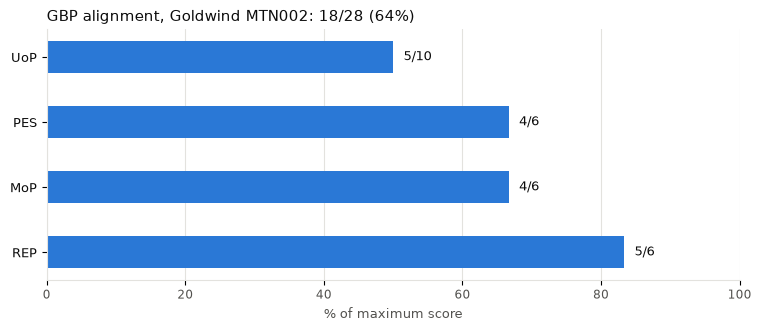

Confidence counts:
confidence
high      12
medium     2

criterion_id pillar                         criterion  score confidence
          M3    MoP              Unallocated proceeds      0       high
          U5    UoP         Refinancing and look-back      0       high
          P1    PES      Process and responsible body      1       high
          P2    PES     Environmental and social risk      1     medium
          R3    REP                   External review      1     medium
          U1    UoP                 Taxonomy category      1       high
          U2    UoP               Project specificity      1       high
          U4    UoP Directness of link to green asset      1       high


In [7]:
gbp = pd.read_csv(ROOT / "data/processed/gbp_scores_summary.csv")
det = pd.read_csv(ROOT / "data/processed/gbp_scores_detail.csv")
print(gbp.to_string(index=False))
print()

is_tot = gbp["pillar"].astype(str).str.upper().str.contains("TOTAL")
pil = gbp[~is_tot].copy()
tot = gbp[is_tot].iloc[0]
pil["pct_calc"] = pil["score"] / pil["max"] * 100

fig, ax = plt.subplots(figsize=(7.5, 3.2), constrained_layout=True)
ypos = range(len(pil))[::-1]
ax.barh(list(ypos), pil["pct_calc"], color=BLUE, height=0.5)
for y, (_, r) in zip(ypos, pil.iterrows()):
    ax.text(r["pct_calc"] + 1.5, y, f"{int(r['score'])}/{int(r['max'])}",
            va="center", fontsize=9, color=INK)
ax.set_yticks(list(ypos))
ax.set_yticklabels(pil["pillar"], fontsize=9.5, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% of maximum score", fontsize=9, color=MUTED)
ax.tick_params(axis="x", labelsize=8.5, labelcolor=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(GRID)
ax.set_title(f"GBP alignment, Goldwind MTN002: {int(tot['score'])}/{int(tot['max'])} "
             f"({tot['score'] / tot['max'] * 100:.0f}%)", loc="left", fontsize=11, color=INK)
fig.savefig(ROOT / "outputs/charts/gbp_pillars.png", dpi=160, facecolor="white")
plt.show()

print("Confidence counts:")
print(det["confidence"].value_counts().to_string())
print()
gaps = det[det["score"] < 2][["criterion_id", "pillar", "criterion", "score", "confidence"]]
print(gaps.sort_values(["score", "criterion_id"]).to_string(index=False))

## 5. Use-of-proceeds classifier

Task: assign the projects a bond finances to categories of the green-project catalogue (`catalogue_categories.csv`, 47 rows, two levels). An LLM reads the use-of-proceeds text (prompt v1) and returns L1/L2 categories. Gold labels for 10 bonds were written by the author; 4 bonds also carry a category declared in their own prospectus (`declared_l2`).

The cell recomputes every metric from `eval_per_bond.csv` and checks the result against `eval_summary.txt` (it matches).

| | L2 exact | L2 overlap | Precision | Recall |
|---|---|---|---|---|
| All 10 bonds | 4/10 (95% CI 17-69%) | 7/10 | 7/11 | 7/16 |

L1 metrics are identical to L2 on every number: no bond has the category right and the sub-category wrong.

- **Recall is capped by the prompt.** Gold has 16 labels over 10 bonds (5 bonds have two or more). The model returns one L2 for 9 of 10 bonds, 11 labels in total, so recall cannot exceed 11/16 = 69%; it is 44%.
- **All four exact matches are single-label bonds whose gold confidence is high** (Fuzhou Metro, Jinneng Power, PowerChina New Energy, Yuexiu New Energy). On the 5 high-confidence bonds the model matches 4 (CI about 38-96%); on the 5 medium or low-confidence bonds it matches 0. Those five are water, waste or mixed-purpose bonds where the gold label itself is uncertain and the catalogue overlaps (for example 3.2 and 6.4 both cover waste incineration), so model error and taxonomy ambiguity cannot be separated here.
- **Independent anchor:** against `declared_l2` the LLM agrees on 3 of 4 bonds and gold on 4 of 4. The one miss is `fsh_water_2026` (LLM 2.3, declared and gold 6.4). Three of those four bonds are the easy ones.

**Limits.** n = 10 is too small to tell 20% from 60%. A single annotator wrote the gold labels, and `henan_water_2021` was revised after seeing LLM output (per its label note, the revised item was the non-green share, 30% to 0%, not the L2 labels). Report these as descriptive counts, not accuracy.

In [8]:
from math import sqrt

pb = pd.read_csv(ROOT / "outputs/eval_per_bond.csv", dtype=str)

def S(x):
    return set() if pd.isna(x) or x == "" else set(str(x).split(";"))

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    a = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - a) / d, (c + a) / d

res = {}
for lvl in ("l1", "l2"):
    tp = ng = npred = exact = overlap = 0
    for _, r in pb.iterrows():
        g, p = S(r[f"gold_{lvl}"]), S(r[f"pred_{lvl}"])
        tp += len(g & p); ng += len(g); npred += len(p)
        exact += g == p
        overlap += len(g & p) > 0
    prec, rec = tp / npred, tp / ng
    res[lvl] = dict(exact=exact, overlap=overlap, tp=tp, npred=npred, ng=ng,
                    prec=prec, rec=rec, f1=2 * prec * rec / (prec + rec))

n = len(pb)
for lvl, r in res.items():
    lo, hi = wilson(r["exact"], n)
    print(f"{lvl.upper()}: exact {r['exact']}/{n} (95% CI {lo:.0%}-{hi:.0%}), "
          f"overlap {r['overlap']}/{n}, precision {r['tp']}/{r['npred']}={r['prec']:.0%}, "
          f"recall {r['tp']}/{r['ng']}={r['rec']:.0%}, F1 {r['f1']:.2f}")

l2 = res["l2"]
ok = (l2["exact"], l2["overlap"], l2["tp"], l2["npred"], l2["ng"]) == (4, 7, 7, 11, 16)
print("Matches eval_summary.txt (L2 exact 4, overlap 7, P 7/11, R 7/16):", ok)

print()
print("Gold labels per bond (L2):", pb["gold_l2"].map(lambda x: len(S(x))).tolist())
print("Pred labels per bond (L2):", pb["pred_l2"].map(lambda x: len(S(x))).tolist())
print()
show = ["bond_id", "gold_l2", "pred_l2", "declared_l2", "error_type", "gold_conf", "revised"]
print(pb[show].to_string(index=False))

L1: exact 4/10 (95% CI 17%-69%), overlap 7/10, precision 7/11=64%, recall 7/16=44%, F1 0.52
L2: exact 4/10 (95% CI 17%-69%), overlap 7/10, precision 7/11=64%, recall 7/16=44%, F1 0.52
Matches eval_summary.txt (L2 exact 4, overlap 7, P 7/11, R 7/16): True

Gold labels per bond (L2): [1, 1, 1, 3, 2, 2, 2, 1, 1, 2]
Pred labels per bond (L2): [1, 1, 1, 2, 1, 1, 1, 1, 1, 1]

                  bond_id     gold_l2 pred_l2 declared_l2             error_type gold_conf revised
           fsh_water_2026         6.4     2.3         6.4               disjoint      high   False
        fuzhou_metro_2026         6.2     6.2         6.2                  exact      high   False
       jinneng_power_2026         4.2     4.2         4.2                  exact      high   False
               cecep_2026 3.2;4.2;6.4 2.5;4.2         NaN          overlap_mixed       low   False
            cepg_env_2025     3.2;6.4     6.4         NaN    subset_missing_gold       med   False
  changzhou_binjiang_2020     1.3

## Conclusions and limitations

1. **Credit profile.** Debt/EBITDA is 4.00x LTM against 3.95x in FY2025 and a 2022-2024 range of 5.4-5.9x. Leverage is flat since FY2025 because debt grew 7.4% against EBITDA +5.8%.
2. **2025 deleveraging was an earnings recovery.** EBITDA explains -1.57x of the -1.90x change and the debt effect is largely a swap into perpetuals. Counting perpetuals as debt, EBITDA explains -1.65x and debt -0.05x.
3. **MTN002 is not material to credit.** Across equity and debt treatment, debt/EBITDA stays within 3.90x-4.11x. The prospectus claim of -1.02 points in liabilities/assets could not be reproduced (-0.43 to -0.60 points).
4. **Green-bond documentation is mid-range with weak fund handling.** 18/28 (64%); Use of Proceeds is the weakest pillar, and unallocated-proceeds management (M3) and refinancing (U5) both score 0.
5. **The classifier works on single-purpose bonds and is unproven elsewhere.** 4/10 exact, 7/10 overlapping, on 10 bonds with one annotator.

**Not done or not verifiable from these sources**
- MTN002 is not in any balance sheet used here; the pro-forma is an estimate under stated assumptions, and the accounting treatment is an intention, not a confirmed fact.
- H1 2026 figures are unaudited.
- The composition of 投资收益 and the 10.8 亿元 FY2025 fair-value gain have not been checked in the annual report notes.
- The company-reported EBITDA interest coverage (8.44x EBITDA and 4.94x EBIT interest coverage in H1 2026) is lower than the module's figure; the interest denominator appears to be about RMB 595m against 464m, possibly capitalised interest. This is inferred, not stated in the report.
- One bond scored on GBP; ten bonds in the classifier evaluation.